Connexion OK


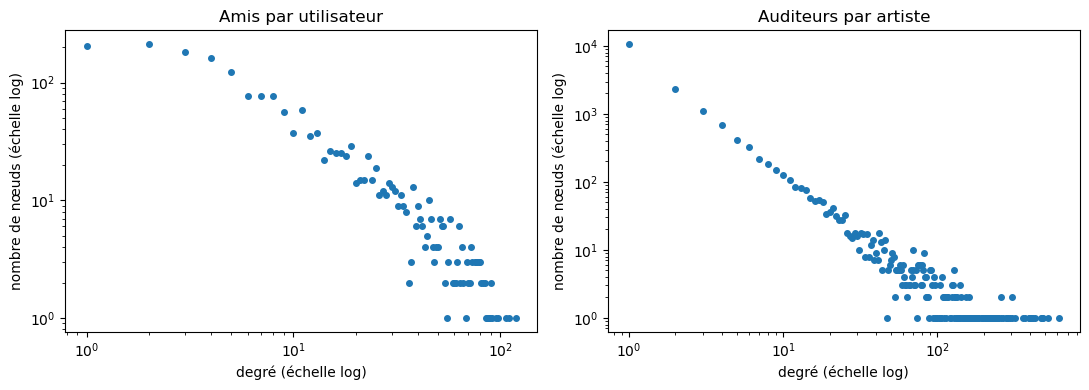

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

from getpass import getpass
from neo4j import GraphDatabase

mdp = getpass("Mot de passe Neo4j : ")
driver = GraphDatabase.driver("bolt://localhost:7687", auth=("neo4j", mdp))
driver.verify_connectivity()
print("Connexion OK")

def run(q):
    with driver.session() as s:
        return pd.DataFrame(s.run(q).data())

friends = run("MATCH (u:User) RETURN COUNT { (u)-[:IS_FRIEND]-() } AS degree")
listeners = run("MATCH (a:Artist) RETURN COUNT { ()-[:LISTEN_TO]->(a) } AS degree")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for axis, df, titre in [(ax[0], friends, "Amis par utilisateur"),
                        (ax[1], listeners, "Auditeurs par artiste")]:
    counts = df["degree"].value_counts().sort_index()
    axis.loglog(counts.index, counts.values, "o", markersize=4)
    axis.set_xlabel("degré (échelle log)")
    axis.set_ylabel("nombre de nœuds (échelle log)")
    axis.set_title(titre)
plt.tight_layout()
plt.savefig("../results/figures/degree_distribution.png", dpi=150)
plt.show()

In [4]:
import sys
print(sys.executable)

c:\Users\DELL\anaconda3\python.exe


In [6]:
%pip install neo4j python-dotenv graphdatascience

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.2 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.2 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.2 MB 645.7 kB/s eta 0:00:03
   -------------- ------------------------- 0.8/2.2 MB 859.5 kB/s eta 0:00:02
   ------------------- -------------------- 1.0/2.2 MB 825.2 kB/s eta 0:00:02
   ------------------- -------------------- 1.0/2.2 MB 825.2 kB/s eta 0:00:02
   ------------------------ --------------- 1.3/2.2 MB 798.6 kB/s eta 0:00:02
   ---------------------------- ----------- 1.6/2.2 MB 822.3 kB/s eta 0:00:01
   --------------------------------- ------ 1.8/2.2 MB 853.0 kB/s eta 0:00:01
   --------------------------------- ------ 1.8/2.2 MB 853.0 kB/s eta 0:00:01
   -------------------------------------- - 2.1/2.2 MB 883.1 kB/s eta 0:00:01
   -------------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.52.2 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.
